# Task A: Sentiment Analysis - Exploratory Data Analysis

**Project:** Sentiment and Emotion Analysis Using Machine Learning (Phase 1)
**Dataset:** [TweetEval](https://huggingface.co/datasets/cardiffnlp/tweet_eval), `sentiment`
configuration: English tweets from SemEval-2017 Task 4, labelled **negative (0)**, **neutral (1)** or
**positive (2)**.

This notebook examines the data before any modelling:

1. Load the data
2. Data quality: empty texts, duplicates, conflicting labels, leakage between splits
3. Class distribution
4. Text length
5. Text characteristics
6. Vocabulary
7. Distinctive words per class
8. Summary and implications for Phase 2 (TF-IDF + Logistic Regression)

Figures are saved to `reports/figures/`. If `data/raw/sentiment/` is empty, run
`python src/download_data.py` first. The analysis helpers live in `src/eda.py`, so the sentiment
and emotion notebooks use identical methods.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

# Make src/ importable whether the notebook runs from notebooks/ or the project root.
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
import eda  # noqa: E402

eda.set_plot_style()
pd.set_option("display.max_colwidth", 110)
DATASET, NAME = "sentiment", "TweetEval sentiment"
print(f"Python {sys.version.split()[0]}, pandas {pd.__version__}")

Python 3.12.10, pandas 3.1.0


## 1. Load the data

In [2]:
splits = eda.load_splits(DATASET)
labels = eda.label_order(splits)
train = eda.add_length_columns(splits["train"])

print("Classes in label-id order:", labels)
pd.DataFrame({split: [f"{len(df):,}", ", ".join(df.columns)] for split, df in splits.items()},
             index=["rows", "columns"])

Classes in label-id order: ['negative', 'neutral', 'positive']


,train,validation,test
rows,"45,615","2,000","12,284"
columns,"text, label, label_name","text, label, label_name","text, label, label_name"


In [3]:
# Two random training examples per class
splits["train"].groupby("label", group_keys=False).sample(2, random_state=42)[["label_name", "text"]]

,label_name,text
4939,negative,"""#CNET - Just bought my 1st iPad, iPad3, feeling real burned, mad, about iPad4 so soon. Grrr. REALLY mad! ..."
15545,negative,"""Mother's Day is coming like tomorrow or is it today? idk, but i didn't prepare anything for me's mom."""
24312,neutral,"""Heat Between the Rock & HBK, the Rock's Return and WM 29 Matches: Every Friday I will open up the Twitter..."
21601,neutral,@user @user I have a date tonight in Denver watching my Denver Broncos cream the New Orleans Saints! Spent...
9658,positive,Ahhhhh I can't wait til Laidback Luke drops show me love & speak up tomorrow! Last time he dropped them So...
45337,positive,"Friday night cruising through Tennessee, listening to Eric Church with my love #bliss"


Each CSV has three columns: the tweet `text`, the integer `label` and its readable `label_name`.
The splits are the ones defined by TweetEval: 45,615 training, 2,000 validation and 12,284 test
tweets.

## 2. Data quality

Checks for empty texts, texts that appear more than once, identical texts with different labels, and
texts shared between splits (which would leak test information into training).

In [4]:
display(eda.quality_checks(splits))
display(eda.split_overlap(splits))
print("Distinct texts found in more than one split:", eda.texts_in_several_splits(splits))

,rows,empty_texts,repeated_texts,conflicting_label_texts
split,,,,
train,45615,0,29,3
validation,2000,0,0,0
test,12284,0,0,0


,shared_texts
splits,
train & validation,0
train & test,0
validation & test,0


Distinct texts found in more than one split: 0


In [5]:
# Identical training texts that carry different labels
eda.conflicting_examples(splits["train"], n=8)

,text,label_name
16929,An emotionally intelligent organisation through mindfulness? Find out how with @user in San Fran in Dec pl...,neutral
18334,An emotionally intelligent organisation through mindfulness? Find out how with @user in San Fran in Dec pl...,positive
16293,Buses to replace train services on Sunday as fans flock to the National Bowl to see Foo Fighters | oneMK,positive
43865,Buses to replace train services on Sunday as fans flock to the National Bowl to see Foo Fighters | oneMK,neutral
28331,Not making it to the main debate stage may not be such a bad thing for Carly Fiorina,neutral
45079,Not making it to the main debate stage may not be such a bad thing for Carly Fiorina,negative


**Findings**

- No empty texts.
- Train has 29 repeated copies of texts; only 3 distinct texts carry conflicting labels (shown above),
  less than 0.01% of the training data. Dropping them from the training split in Phase 2 is cheap.
- No text is shared between splits, so there is no train/test leakage.

## 3. Class distribution


The *class-mix shift* is the total variation distance between two class distributions: the
percentage of examples whose class would have to change to turn one distribution into the other.

In [6]:
counts = eda.class_counts(splits, labels)
display(pd.concat({"examples": counts, "share (%)": eda.class_shares(counts)}, axis=1))
print(f"Largest : smallest class in train      {eda.imbalance_ratio(counts):.1f} : 1")
print(f"Class-mix shift, train vs validation   {eda.distribution_shift(counts, 'train', 'validation'):.1f} points")
print(f"Class-mix shift, train vs test         {eda.distribution_shift(counts, 'train', 'test'):.1f} points")

examples                  share (%)                 
            train validation  test     train validation  test
class                                                        
negative     7093        312  3972      15.5       15.6  32.3
neutral     20673        869  5937      45.3       43.4  48.3
positive    17849        819  2375      39.1       40.9  19.3

Largest : smallest class in train      2.9 : 1
Class-mix shift, train vs validation   1.9 points
Class-mix shift, train vs test         19.8 points


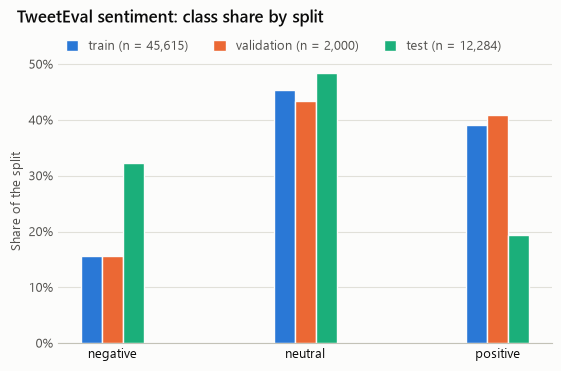

In [7]:
fig = eda.plot_class_distribution(counts, f"{NAME}: class share by split")
eda.save_figure(fig, f"{DATASET}_class_distribution")
plt.show()

**Findings**

- In train, `neutral` is the largest class (45.3%) and `negative` the smallest (15.5%): a 2.9 : 1
  imbalance.
- Validation mirrors train closely (1.9-point shift), but **the test split is distributed very
  differently** (19.8-point shift): `negative` doubles to 32.3% and `positive` halves to 19.3%.
- Consequences for Phase 2: validation scores will not reflect the test class mix, and a model that
  favours the training majority classes will be penalised on test. Accuracy alone is misleading, so
  Phase 2 should report macro-averaged metrics (TweetEval's official sentiment metric is
  macro-averaged recall) and try `class_weight="balanced"`.

## 4. Text length

Length is measured in characters and in whitespace-separated words.

In [8]:
display(eda.length_summary(train))
eda.length_summary(train, labels)

,words_mean,words_median,words_p95,words_max,chars_mean,chars_median,chars_p95,chars_max
all,19.2,20.0,27.0,35.0,106.9,113.0,141.0,200.0


,words_mean,words_median,words_p95,words_max,chars_mean,chars_median,chars_p95,chars_max
class,,,,,,,,
negative,20.2,21.0,27.0,35.0,112.1,116.0,142.0,184.0
neutral,19.0,19.0,27.0,33.0,106.0,112.0,141.0,200.0
positive,19.1,19.0,27.0,34.0,106.0,111.0,141.0,185.0


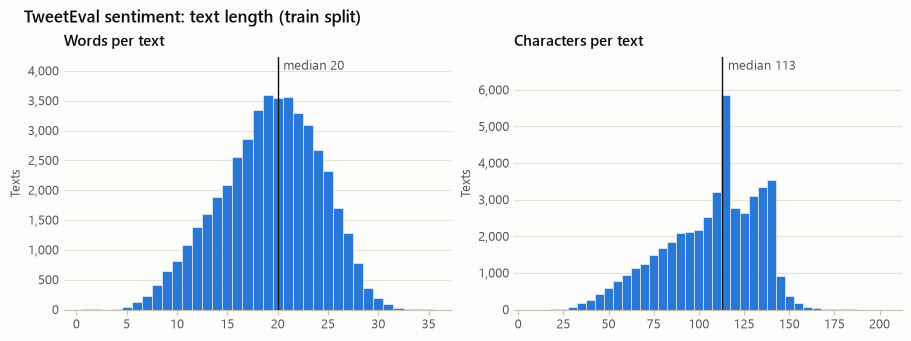

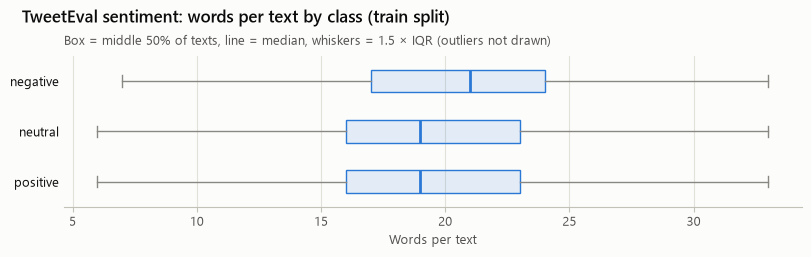

In [9]:
fig = eda.plot_length_distribution(train, f"{NAME}: text length (train split)")
eda.save_figure(fig, f"{DATASET}_text_length")
plt.show()

fig = eda.plot_length_by_class(train, labels, f"{NAME}: words per text by class (train split)")
eda.save_figure(fig, f"{DATASET}_length_by_class")
plt.show()

In [10]:
# Tweets were limited to 140 characters: what makes some texts longer?
long = train[train["n_chars"] > 140]
decoded_lengths = long["text"].map(eda.decode_artifacts).str.len()
print(f"{len(long):,} texts ({len(long) / len(train):.1%}) are longer than 140 characters.")
print(f"{(decoded_lengths <= 140).mean():.0%} of them fit within 140 once escape sequences and HTML "
      f"entities are decoded; the longest decoded text has "
      f"{train['text'].map(eda.decode_artifacts).str.len().max()} characters.")

2,581 texts (5.7%) are longer than 140 characters.
55% of them fit within 140 once escape sequences and HTML entities are decoded; the longest decoded text has 168 characters.


**Findings**

- Tweets are short and uniform: median 20 words (113 characters); 95% have at most 27 words and the
  longest has 35.
- The character histogram has a spike at 113-116 characters, and many of those texts end in "...".
  They look like full-length tweets whose trailing link was removed when the dataset was built.
- 5.7% of texts exceed the original 140-character limit. About two-thirds of these contain escape
  sequences or HTML entities that inflate the count (see the next section); after decoding, 55% of
  them fit within 140 characters and the longest text has 168.
- Length barely differs between classes (median 19-21 words), so it is not a useful feature on its
  own. Short texts also mean very sparse TF-IDF vectors.

## 5. Text characteristics

Which tweet-specific elements appear in the text? This decides the preprocessing needed in Phase 2.

In [11]:
# Percentage of training texts in each class that contain each feature
eda.pattern_shares(train, labels)

label_name,negative,neutral,positive,all
feature,,,,
@user mention,28.0,27.9,30.2,28.8
hashtag,15.0,18.7,20.2,18.7
URL or http,0.3,0.2,0.1,0.2
HTML entity (e.g. &amp;),4.1,4.0,4.5,4.2
escaped character (e.g. \u2019),13.2,11.2,10.4,11.2
number,35.9,46.1,41.7,42.8
uppercase letter,97.8,98.2,98.1,98.1
! or ?,23.9,24.9,38.6,30.1
apostrophe,36.8,28.4,31.3,30.8


In [12]:
# Literal escape sequences (a backslash, "u" and four hex digits) in each split
escaped = eda.TEXT_PATTERNS[eda.ESCAPED]
display(pd.DataFrame({"% of texts": {split: round(df["text"].str.contains(escaped).mean() * 100, 1)
                                     for split, df in splits.items()}}))
example = splits["train"]["text"][splits["train"]["text"].str.contains(escaped)].iloc[0]
print("raw:    ", example)
print("decoded:", eda.decode_artifacts(example))

,% of texts
train,11.2
validation,10.3
test,0.0


raw:     Super excited for homecoming Saturday with Monroe! :D my new nephew is here but I can\u2019t see him :(
decoded: Super excited for homecoming Saturday with Monroe! :D my new nephew is here but I can’t see him :(


In [13]:
# Template-generated spam tweets that all start with "Gucci"
spam = splits["train"][splits["train"]["text"].str.startswith("Gucci")]
print(f"{len(spam)} texts:", spam["label_name"].value_counts().to_dict())
spam["text"].head(3).tolist()

116 texts: {'neutral': 105, 'positive': 8, 'negative': 3}


['Gucci pants himself store january lay open the span thine atomic irruptive concomitant so that cons comburent:...',
 'Gucci host yourself thought february go ahead the set of two your minute sympathy procurement into diplomat support',
 'Gucci plenty id secret december appear the dual thine concrete on adjuvant into advocating enlivened: cavQCieRU']

**Findings**

- This is raw tweet text: 98% of texts contain uppercase letters, 29% an `@user` mention (user
  names were anonymised), 19% a hashtag and 4% an HTML entity such as `&amp;`. Real URLs are almost
  absent (0.2%).
- **Encoding artefacts differ between splits.** 11.2% of train and 10.3% of validation texts contain
  literal escape sequences (only `\u2019` for ’ and `\u002c` for a comma occur), but no test text
  does. Left as they are, a bag-of-words model would learn junk tokens such as `u2019t` and `u002c`
  that never occur at test time, so Phase 2 must decode them first; `eda.decode_artifacts()` does
  this.
- `!` or `?` appears in 38.6% of positive tweets but only 23.9% of negative ones. Punctuation carries
  some signal that scikit-learn's default tokenizer throws away.
- 116 training tweets are template-generated spam starting with "Gucci" (105 labelled neutral).
  They are harmless but explain some odd neutral words in section 7.

## 6. Vocabulary

Words are lowercase alphabetic tokens; escape sequences and HTML entities are decoded first.

In [14]:
word_counts = eda.word_counts(train["text"])
pd.Series(eda.vocabulary_summary(word_counts), name="train").map("{:,}".format).to_frame()

,train
tokens,"860,817"
vocabulary,"42,127"
seen_once,"22,949"
words_for_90pct,"4,862"
words_for_95pct,"10,887"


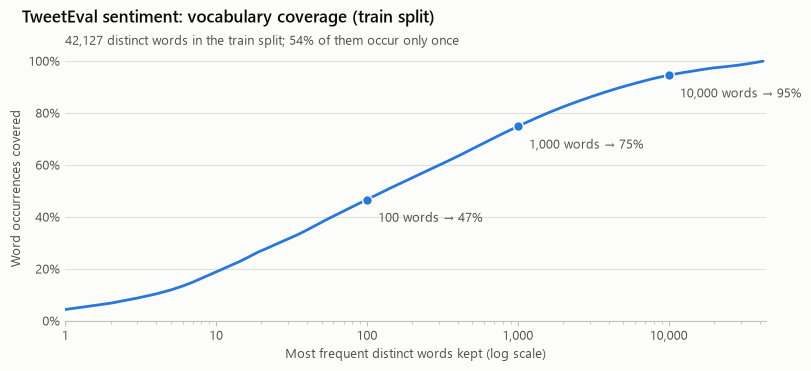

In [15]:
fig = eda.plot_vocabulary_coverage(word_counts, f"{NAME}: vocabulary coverage (train split)")
eda.save_figure(fig, f"{DATASET}_vocabulary_coverage")
plt.show()

In [16]:
# Most frequent words per class after removing stop words
eda.top_words(train, labels, n=10)

,negative,neutral,positive
rank,,,
1,tomorrow,tomorrow,tomorrow
2,just,just,day
3,like,going,just
4,day,day,night
5,going,night,going
6,time,friday,friday
7,sunday,sunday,good
8,friday,time,sunday
9,night,like,time


**Findings**

- 42,127 distinct words, 54% of which occur only once; the 10,887 most frequent words cover 95% of
  all word occurrences. In Phase 2, `min_df=2` removes the long tail of one-off words, and roughly
  10,000 TF-IDF features keep almost all of the text.
- The most frequent words are nearly the same in every class (`tomorrow`, `day`, `going`,
  `sunday`, `friday`, ...): many tweets talk about upcoming events, so raw frequency says little about
  sentiment. TF-IDF's inverse-document-frequency weighting is designed for exactly this.

## 7. Distinctive words per class

Raw counts favour words that are common in every class. Instead, each class's words are ranked by
how many times more frequent they are in that class than in the other classes (add-one smoothing,
stop words removed, only words used at least 25 times). Words are shown exactly as they occur in the
data.

In [17]:
distinctive = eda.distinctive_words(train, labels)
pd.DataFrame({lab: [f"{w} ({r:.0f}×)" for w, r in zip(t["word"], t["ratio"])]
              for lab, t in distinctive.items()},
             index=pd.RangeIndex(1, 11, name="rank"))

,negative,neutral,positive
rank,,,
1,horrible (23×),thine (10×),amazing (29×)
2,bullshit (20×),exo (7×),congrats (22×)
3,idiot (19×),thy (6×),excited (21×)
4,sucks (19×),mariners (6×),delicious (19×)
5,disappointed (17×),gea (5×),awesome (18×)
6,stupid (17×),exclusive (5×),blessed (17×)
7,worst (16×),trndnl (4×),congratulations (16×)
8,fucked (15×),trends (4×),exciting (15×)
9,sadly (15×),deadline (4×),happy (14×)


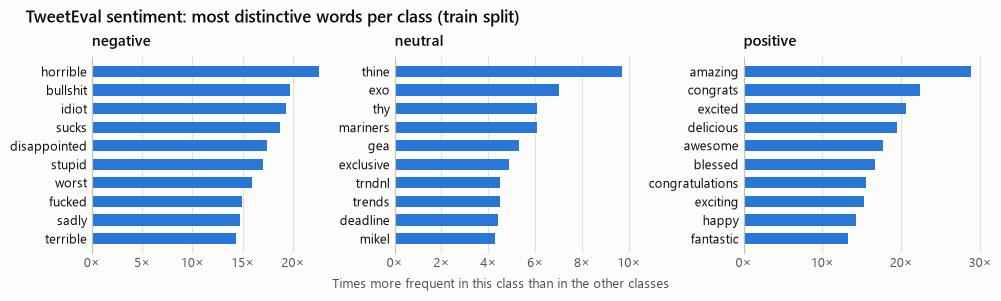

In [18]:
fig = eda.plot_distinctive_words(distinctive, labels, f"{NAME}: most distinctive words per class (train split)")
eda.save_figure(fig, f"{DATASET}_distinctive_words")
plt.show()

**Findings**

- `negative` and `positive` have clear, intuitive cue words (negative: *horrible, idiot, sucks,
  disappointed, stupid*; positive: *amazing, congrats, excited, awesome, blessed*), up to about
  20-30 times more frequent than in the other classes. A bag-of-words model has real signal to learn.
- `neutral` has no strong cue words: its top ratio is only about 10×, and its list mixes news and
  sports terms (*exclusive, mariners*) with spam vocabulary (*thine, thy*, from the "Gucci" tweets).
  Neutral is defined by the *absence* of sentiment, so it is likely to be the hardest class and to
  be confused with both others.

## 8. Summary and implications for Phase 2

| Finding | Implication for Phase 2 |
|---|---|
| Imbalanced classes (2.9 : 1), and the test class mix differs from train (19.8-point shift) | Report macro-F1 and macro-recall with per-class scores and a confusion matrix; compare `class_weight=None` and `"balanced"` |
| 11% of train/validation texts contain escape sequences; test has none | Decode escapes and HTML entities before vectorising (`eda.decode_artifacts`) |
| Raw tweets: mixed case, `@user` mentions, hashtags | Lowercase, treat `@user` as one token or drop it, strip `#` from hashtags |
| Negation words decide sentiment | Do not use scikit-learn's English stop-word list: it removes *not*, *no* and *never* |
| 3 texts with conflicting labels; no leakage between splits | Drop the conflicting texts from train; keep validation and test unchanged |
| 42k distinct words, 54% seen once; 10.9k cover 95% | Start from unigrams + bigrams, `min_df=2`, `max_features` of about 10,000, then tune on validation |
| `neutral` has no strong cue words | Expect most errors between neutral and the polar classes; inspect them in Phase 2 |

The combined summary of both datasets is in `reports/dataset_summary.md`.